# Daily ingest summary

This notebook is a part of the alert-archive verification notebooks:
1. **Baseline vs. frozen:**
    - Just to make sure we're on track with the new alert-archive pipeline.
    - The baseline is a subset of the initial pq dump, so it is a subset of the frozen catalog.
2. **Replay vs frozen:**
    - With the "daily replays" added to the baseline, this version of the **working catalog** now spans the entire original pq dump.
    - This means it can properly be compared to the **frozen catalog**, which was originally built by that same dump.
    - Spoiler alert, we find them to be equivalent :)
3. **Daily ingest summary:** (⭐ you are here)
    - A summary of the working catalog after running the daily ingest process on the **new** alerts.
    - Because we are now going beyond the frozen catalog, this notebook instead explores the partitioning, coverage, etc.

Summary of everything the **daily runs** have added to the working catalog since the replay, i.e.
alerts beyond the frozen catalog. Rerun it after later daily runs; it finds them from `ingested.jsonl`.

The frozen catalog can't check these alerts, so they're checked against their sources instead: the
converter's chunks in `landing/` and the raw alert archive (one `<alertId>.avro.gz` per alert, and an
alert's `alertId` is its `diaSourceId`).

| | Path |
|---|---|
| Working | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/working` |
| Landing (converter output) | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/landing` |
| Working right after the replay (snapshot, optional) | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/replay_working` |
| Raw alert archive | `/sdf/data/rubin/shared/alert-archive/v2/alerts` |
| Frozen | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive/rubin_alert_archive` |

## Sections:
0. Set up & last-run timestamps
1. The daily runs and the chunks they ingested
2. Did every raw alert make it in?
3. Was every alert ingested exactly once?
4. The new alerts: nights, bands, sky
5. Format 1101
6. Partitioning
7. Spot check against the source chunks
8. Summary

## 0. Set up & last-run timestamps

In [1]:
import os
import subprocess
from pathlib import Path

import alert_archive
import hats
import lsdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from alert_archive.config import PathConfig
from alert_archive.daily.increment import leaf_files
from alert_archive.daily.run import CHUNK_NAME
from alert_archive.state import PipelineState

paths = PathConfig()
WORKING, LANDING = paths.working_dir, paths.landing_dir
AFTER_REPLAY = paths.root / "replay_working"
FROZEN = Path("/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive/rubin_alert_archive")
RAW = Path("/sdf/data/rubin/shared/alert-archive/v2/alerts")
THRESHOLD = 200_000

repo = Path(alert_archive.__file__).resolve().parents[2]
git = lambda *args: subprocess.run(["git", "-C", repo, *args], capture_output=True, text=True).stdout.strip()
print(f"alert_archive from {repo}: {git('rev-parse', '--abbrev-ref', 'HEAD')} @ {git('log', '-1', '--format=%h %s')}")

working = hats.read_hats(WORKING)
runs = PipelineState(paths.state_dir).runs()
dump_chunks = {p.name for p in paths.dump_dir.glob("*.parquet")}
dump_prefixes = {name.split("__")[0] for name in dump_chunks}
# The baseline and replay ingested only dump chunks; every run after the last of those is a daily run.
last_dump_run = max(i for i, r in enumerate(runs) if r.chunks and set(r.chunks) <= dump_chunks)
daily_runs = runs[last_dump_run + 1 :]
ingested = {c for r in runs for c in r.chunks}
print(f"{len(runs)} runs logged: baseline + {last_dump_run} replay runs + {len(daily_runs)} daily runs")


def read_column(files, column):
    """One column (dotted paths allowed for nested fields) from the given files, as a flat arrow array."""
    field = column.partition(".")[2]
    chunks = []
    for path in files:
        col = pq.read_table(path, columns=[column]).column(0).combine_chunks()
        if field and pa.types.is_struct(col.type):
            col = pc.struct_field(col, field)
        if pa.types.is_list(col.type) or pa.types.is_large_list(col.type):  # catalog: one element per alert
            col = pc.list_flatten(col)
        chunks.append(col)
    return pa.concat_arrays(chunks)

alert_archive from /sdf/home/o/olynn/alert-archive: olivia/daily-run @ e881cf0 Add daily.sbatch to run the daily pipeline once
74 runs logged: baseline + 72 replay runs + 1 daily runs


In [18]:
def show_time(ts):
    t = pd.Timestamp(ts, unit="s", tz="UTC") if not isinstance(ts, pd.Timestamp) else ts
    return f"{t.tz_convert('America/Los_Angeles'):%Y-%m-%d %H:%M %Z} ({t:%Y-%m-%d %H:%M} UTC)"


# Raw archive: the prefix directory changed most recently, then its newest alert.
prefix_dirs = [e for e in os.scandir(RAW) if e.is_dir() and e.name.isdigit()]
newest_dir = max(prefix_dirs, key=lambda e: e.stat().st_mtime)
raw_files = [e for e in os.scandir(newest_dir.path) if e.name.endswith(".avro.gz")]
newest_raw = max(raw_files, key=lambda e: e.stat().st_mtime)

# landing/: the converter's newest chunk, and its manifest (rewritten every time the converter runs).
chunk_files = [p for p in LANDING.glob("*.parquet") if not p.name.startswith(".")]
newest_chunk = max(chunk_files, key=lambda p: p.stat().st_mtime) if chunk_files else None
manifest = LANDING / "manifest.json"

# Catalog: the last run logged, and the last run that ingested anything.
last_run = runs[-1]
last_ingest = next(r for r in reversed(runs) if r.num_rows)

print(f"Notebook last run: {show_time(pd.Timestamp.now(tz='UTC'))}\n")
print(f"1. Raw alerts   {RAW}")
print(f"     newest alert       {show_time(newest_raw.stat().st_mtime)}  {newest_dir.name}/{newest_raw.name}")
print(f"     newest prefix      {newest_dir.name}: {len(raw_files):,} alerts")
print("        |  converter (Avro -> parquet chunks)")
print("        v")
print(f"2. landing/     {LANDING}")
if newest_chunk:
    print(f"     newest chunk       {show_time(newest_chunk.stat().st_mtime)}  {newest_chunk.name}")
if manifest.exists():
    print(f"     converter last ran {show_time(manifest.stat().st_mtime)}  (manifest.json)")
print("        |  daily run (ingest new chunks)")
print("        v")
print(f"3. Catalog      {WORKING}")
print(f"     last run           {show_time(pd.Timestamp(last_run.started))}  {last_run.run_id} ({last_run.num_rows:,} alerts)")
if last_ingest is not last_run:
    print(f"     last ingest        {show_time(pd.Timestamp(last_ingest.started))}  {last_ingest.run_id} ({last_ingest.num_rows:,} alerts)")
print(f"     total              {working.catalog_info.total_rows:,} alerts")


Notebook last run: 2026-11-03 09:17 PST (2026-11-03 17:17 UTC)

1. Raw alerts   /sdf/data/rubin/shared/alert-archive/v2/alerts
     newest alert       2026-10-31 00:41 PDT (2026-10-31 07:41 UTC)  171145/171145650193825820.avro.gz
     newest prefix      171145: 27,438 alerts
        |  converter (Avro -> parquet chunks)
        v
2. landing/     /sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/landing
     newest chunk       2026-11-02 13:13 PST (2026-11-02 21:13 UTC)  171145__00000000-00027438.parquet
     converter last ran 2026-11-02 13:13 PST (2026-11-02 21:13 UTC)  (manifest.json)
        |  daily run (ingest new chunks)
        v
3. Catalog      /sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/working
     last run           2026-11-02 14:52 PST (2026-11-02 22:52 UTC)  20261102T225212Z (279,959 alerts)
     total              16,746,928 alerts


## 1. The daily runs and the chunks they ingested

One row per daily run since the replay, then one row per chunk: ingested, or still waiting in `landing/`.

In [3]:
pd.DataFrame(
    [
        {
            "run_id": r.run_id,
            "started (UTC)": r.started[:19].replace("T", " "),
            "chunks": len(r.chunks),
            "alerts": r.num_rows,
            "format IDs": dict(r.schema_id_counts),
            "skipped": dict(r.skipped) or "",
        }
        for r in daily_runs
    ]
)

,run_id,started (UTC),chunks,alerts,format IDs,skipped
0,20261102T225212Z,2026-11-02 22:52:12,7,279959,{1101: 279959},


In [4]:
chunk_run = {c: r.run_id for r in daily_runs for c in r.chunks}
in_landing = {p.name for p in LANDING.glob("*.parquet") if not p.name.startswith(".")}


def chunk_status(name):
    if name in chunk_run:
        return "ingested" if name in in_landing else "ingested, no longer in landing/"
    if name in ingested:
        return "ingested by the baseline or replay"
    return "waiting" if CHUNK_NAME.fullmatch(name) else "skipped: unexpected name"


chunks = pd.DataFrame(
    [
        {
            "chunk": name,
            "prefix": name.split("__")[0],
            "footer rows": pq.read_metadata(LANDING / name).num_rows if name in in_landing else pd.NA,
            "run_id": chunk_run.get(name, ""),
            "status": chunk_status(name),
        }
        for name in sorted(set(chunk_run) | in_landing)
    ]
)
print(chunks["status"].value_counts().to_string())
chunks

status
ingested    7


,chunk,prefix,footer rows,run_id,status
0,171141__00000000-00050000.parquet,171141,50000,20261102T225212Z,ingested
1,171141__00050000-00100000.parquet,171141,50000,20261102T225212Z,ingested
2,171141__00100000-00150000.parquet,171141,50000,20261102T225212Z,ingested
3,171141__00150000-00200000.parquet,171141,50000,20261102T225212Z,ingested
4,171141__00200000-00250000.parquet,171141,50000,20261102T225212Z,ingested
5,171141__00250000-00252521.parquet,171141,2521,20261102T225212Z,ingested
6,171145__00000000-00027438.parquet,171145,27438,20261102T225212Z,ingested


## 2. Did every raw alert make it in?

For every raw-archive prefix that isn't in the dump (so the converter's job), compare the raw `alertId`s
with the `diaSourceId`s in the chunks the daily runs ingested and in the chunks still waiting. **Missing**
alerts are in the raw archive but in no chunk (e.g. archived after the converter ran); **extra** ones are in
a chunk but not in the raw archive. Listing the raw directories takes a minute or two.

In [5]:
ingested_files = [LANDING / c for c in chunk_run if c in in_landing]
waiting_files = [LANDING / c for c in chunks.loc[chunks["status"] == "waiting", "chunk"]]
chunk_ids = {
    "ingested": read_column(ingested_files, "diaSourceId").to_numpy() if ingested_files else np.array([], np.int64),
    "waiting": read_column(waiting_files, "diaSourceId").to_numpy() if waiting_files else np.array([], np.int64),
}
new_ids = chunk_ids["ingested"]


def raw_ids(prefix):
    return np.array([int(e.name.split(".")[0]) for e in os.scandir(RAW / prefix) if e.name.endswith(".avro.gz")])


raw_prefixes = sorted(d for d in os.listdir(RAW) if len(d) == 6 and d.isdigit() and d not in dump_prefixes)
rows = []
for prefix in raw_prefixes:
    raw = raw_ids(prefix)
    mtime = max(e.stat().st_mtime for e in os.scandir(RAW / prefix))
    ing, wait = np.intersect1d(raw, chunk_ids["ingested"]), np.intersect1d(raw, chunk_ids["waiting"])
    rows.append(
        {
            "prefix": prefix,
            "newest raw file": pd.Timestamp(mtime, unit="s", tz="UTC").tz_convert("America/Los_Angeles").strftime("%Y-%m-%d %H:%M"),
            "raw alerts": len(raw),
            "ingested": len(ing),
            "waiting in landing/": len(wait),
            "missing": len(np.setdiff1d(raw, np.concatenate([ing, wait]))),
        }
    )
raw_check = pd.DataFrame(rows).set_index("prefix")
all_raw = np.concatenate([raw_ids(p) for p in raw_prefixes]) if raw_prefixes else np.array([], np.int64)
extra = np.setdiff1d(np.concatenate(list(chunk_ids.values())), all_raw)
print(f"Alerts in ingested or waiting chunks but not in the raw archive: {len(extra):,}")
raw_check

Alerts in ingested or waiting chunks but not in the raw archive: 0


,newest raw file,raw alerts,ingested,waiting in landing/,missing
prefix,,,,,
171141,2026-10-30 00:28,252521,252521,0,0
171145,2026-10-31 00:41,27438,27438,0,0


## 3. Was every alert ingested exactly once?

Row counts from the run log, the catalog's parquet footers and `hats.properties` should agree, and should
equal the catalog right after the replay plus what the daily runs ingested. Every `diaSourceId` in the
catalog should be unique, every new alert should be in the catalog once, and none should be in the frozen
catalog. This reads the `diaSourceId` column of every catalog file.

In [6]:
files = [(px, p) for px, fs in leaf_files(WORKING).items() for p in fs]
id_arrays = [pq.read_table(p, columns=["diaSourceId"]).column(0).to_numpy() for _, p in files]
catalog = pd.DataFrame(
    {
        "diaSourceId": np.concatenate(id_arrays),
        "file": np.repeat(np.arange(len(files)), [len(a) for a in id_arrays]),
    }
)
catalog["is_new"] = catalog["diaSourceId"].isin(new_ids)

after_replay = hats.read_hats(AFTER_REPLAY) if AFTER_REPLAY.exists() else None
counts = {
    "rows logged in ingested.jsonl (all runs)": sum(r.num_rows for r in runs),
    "rows in catalog files": len(catalog),
    "hats_nrows in hats.properties": working.catalog_info.total_rows,
    "rows logged by the daily runs": sum(r.num_rows for r in daily_runs),
    "new alerts found in the catalog": int(catalog["is_new"].sum()),
}
if after_replay is not None:
    counts["catalog after the replay + daily runs"] = after_replay.catalog_info.total_rows + counts["rows logged by the daily runs"]
pd.Series(counts).map("{:,}".format).to_frame("count")

,count
rows logged in ingested.jsonl (all runs),"16,746,928"
rows in catalog files,"16,746,928"
hats_nrows in hats.properties,"16,746,928"
rows logged by the daily runs,"279,959"
new alerts found in the catalog,"279,959"
catalog after the replay + daily runs,"16,746,928"


In [7]:
frozen_files = sorted((FROZEN / "dataset").glob("Norder=*/Dir=*/*.parquet"))
frozen_ids = read_column(frozen_files, "diaSourceId").to_numpy()
checks = {
    "all diaSourceIds in the catalog are unique": catalog["diaSourceId"].is_unique,
    "every new alert is in the catalog": bool(np.isin(new_ids, catalog["diaSourceId"]).all()),
    "no new alert is in the frozen catalog": not np.isin(new_ids, frozen_ids).any(),
    "row counts agree": len(set(list(counts.values())[:3])) == 1
    and (after_replay is None or counts["catalog after the replay + daily runs"] == len(catalog)),
}
pd.Series(checks, name="ok").to_frame()

,ok
all diaSourceIds in the catalog are unique,True
every new alert is in the catalog,True
no new alert is in the frozen catalog,True
row counts agree,True


## 4. The new alerts: nights, bands, sky

From the ingested chunks (section 7 checks that the catalog holds the same values). Nights are integer
`diaSource.midpointMjdTai`.

In [8]:
new = pd.DataFrame(
    {
        "diaSourceId": new_ids,
        **{
            c.split(".")[1]: read_column(ingested_files, c).to_numpy(zero_copy_only=False)
            for c in ["diaSource.midpointMjdTai", "diaSource.band", "diaSource.ra", "diaSource.dec"]
        },
    }
)
new["MJD"] = np.floor(new["midpointMjdTai"]).astype(int)
by_night = new.pivot_table(index="MJD", columns="band", values="diaSourceId", aggfunc="count", fill_value=0)
by_night = by_night[[b for b in "ugrizy" if b in by_night]]
by_night.insert(0, "date", pd.to_datetime(by_night.index - 40587, unit="D").strftime("%Y-%m-%d"))
by_night["total"] = by_night.drop(columns="date").sum(axis=1)
by_night

band,date,g,r,i,z,total
MJD,,,,,,
61343,2026-10-30,11960,105136,135425,0,252521
61344,2026-10-31,0,6850,9250,11338,27438


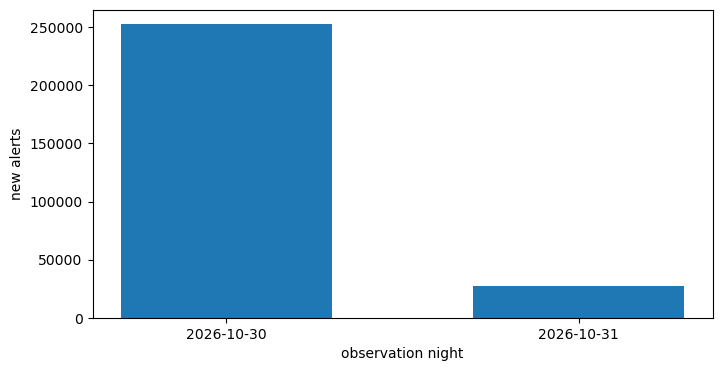

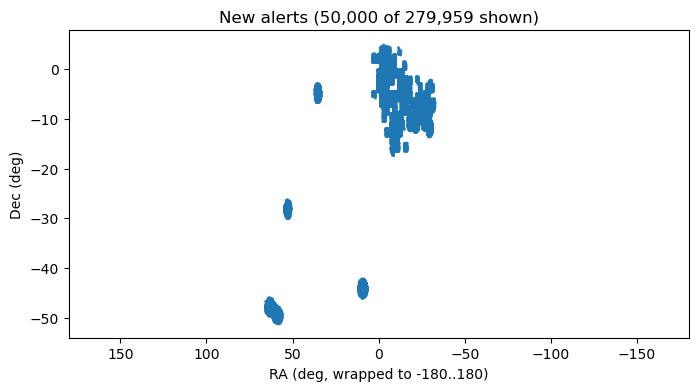

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_night["date"], by_night["total"], width=0.6)
ax.set_xlabel("observation night")
ax.set_ylabel("new alerts")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sample = new.sample(min(len(new), 50_000), random_state=0)
ra = np.where(sample["ra"] > 180, sample["ra"] - 360, sample["ra"])  # keep fields near RA 0 together
ax.scatter(ra, sample["dec"], s=1, alpha=0.3)
ax.set_xlim(180, -180)
ax.set_xlabel("RA (deg, wrapped to -180..180)")
ax.set_ylabel("Dec (deg)")
ax.set_title(f"New alerts ({len(sample):,} of {len(new):,} shown)")
plt.show()

## 5. Format 1101

The converter writes format 1101, which adds four `diaSource` fields that are null for every older (1100)
alert. Read from the partitions that got new alerts: their format IDs, and how many have each new field
filled, against the older alerts in the same partitions.

In [10]:
NEW_FIELDS = ["exposureTime", "reliabilityVersion", "trailAlgorithm", "trail_flag"]
new_files = [files[i][1] for i in np.unique(catalog.loc[catalog["is_new"], "file"])]
touched_pixels = {files[i][0] for i in np.unique(catalog.loc[catalog["is_new"], "file"])}
pixel_files = [p for px, p in files if px in touched_pixels]
fmt = pd.DataFrame(
    {
        "diaSourceId": read_column(pixel_files, "diaSourceId").to_numpy(),
        "schemaId": read_column(pixel_files, "schemaId").to_numpy(),
        **{f: read_column(pixel_files, f"diaSource.{f}").is_valid().to_numpy(zero_copy_only=False) for f in NEW_FIELDS},
    }
)
fmt["alerts"] = np.where(fmt["diaSourceId"].isin(new_ids), "new", "older, same partitions")
print(fmt.groupby("alerts")["schemaId"].value_counts().to_string())
fmt.groupby("alerts")[NEW_FIELDS].mean().map("{:.1%}".format).rename(columns=lambda f: f"{f} filled")

alerts                  schemaId
new                     1101         279959
older, same partitions  1100        7407348


,exposureTime filled,reliabilityVersion filled,trailAlgorithm filled,trail_flag filled
alerts,,,,
new,100.0%,100.0%,100.0%,100.0%
"older, same partitions",0.0%,0.0%,0.0%,0.0%


## 6. Partitioning

Rows and files per partition, now and right after the replay. Daily runs add one file per pixel they touch
and never split a pixel, so partitions keep growing until the weekly re-import.

In [11]:
def partition_stats(catalog_dir):
    out = {}
    for px, fs in leaf_files(catalog_dir).items():
        out[px] = {"rows": sum(pq.read_metadata(p).num_rows for p in fs), "files": len(fs)}
    return pd.DataFrame(out).T


now = partition_stats(WORKING)
before = partition_stats(AFTER_REPLAY) if after_replay is not None else None
stats = ({"after the replay": before} if before is not None else {}) | {"now": now}
pd.DataFrame(
    {
        name: {
            "partitions": len(s),
            "median rows": int(s["rows"].median()),
            "max rows": int(s["rows"].max()),
            f"over {THRESHOLD:,} rows": int((s["rows"] > THRESHOLD).sum()),
            "median files": int(s["files"].median()),
            "max files": int(s["files"].max()),
        }
        for name, s in stats.items()
    }
)

,after the replay,now
partitions,153,153
median rows,82058,82336
max rows,2172010,2172476
"over 200,000 rows",6,6
median files,24,24
max files,49,50


In [12]:
pixel_of_file = pd.Series([str(px) for px, _ in files])
new_per_pixel = pixel_of_file[catalog.loc[catalog["is_new"], "file"]].value_counts()
now.index = now.index.map(str)
touched = now.loc[new_per_pixel.index].assign(**{"new alerts": new_per_pixel})
if before is not None:
    touched["new pixel"] = ~touched.index.isin(before.index.map(str))
print(f"New alerts went into {len(touched)} partitions")
touched.sort_values("new alerts", ascending=False)

New alerts went into 45 partitions


,rows,files,new alerts,new pixel
"Order: 0, Pixel: 4",1064976,12,234573,False
"Order: 2, Pixel: 138",252149,48,19742,False
...,...,...,...,...
"Order: 6, Pixel: 34025",1202,14,17,False
"Order: 7, Pixel: 137336",876,18,8,False


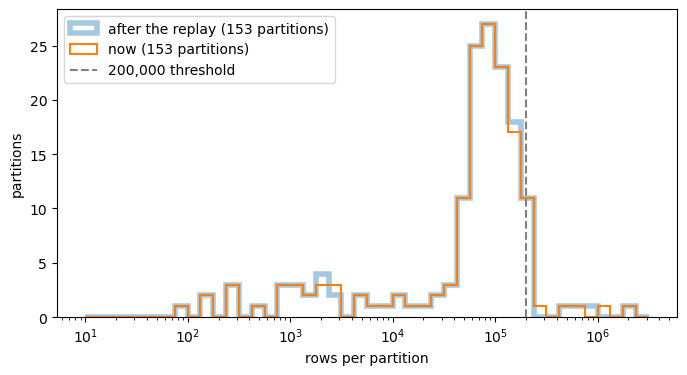

Partitions over 200,000 rows now:


,rows,files
"Order: 0, Pixel: 11",2172476,13
"Order: 0, Pixel: 4",1064976,12
"Order: 0, Pixel: 10",570175,9
"Order: 2, Pixel: 113",432850,7
"Order: 2, Pixel: 138",252149,48
"Order: 6, Pixel: 34329",203630,50


In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(1, 6.5, 45)
styles = {"after the replay": dict(lw=4, alpha=0.4), "now": dict(lw=1.5)}
for name, s in stats.items():
    ax.hist(s["rows"], bins=bins, histtype="step", label=f"{name} ({len(s)} partitions)", **styles[name])
ax.axvline(THRESHOLD, color="gray", ls="--", label=f"{THRESHOLD:,} threshold")
ax.set_xscale("log")
ax.set_xlabel("rows per partition")
ax.set_ylabel("partitions")
ax.legend()
plt.show()

print(f"Partitions over {THRESHOLD:,} rows now:")
now[now["rows"] > THRESHOLD].sort_values("rows", ascending=False)

The catalog's partitions on the sky (`plot_pixels`, colored by HEALPix order) and its coverage map
(`plot_coverage`, from the catalog's MOC). Large order-0 and order-2 pixels are the sparse baseline layout
that the new alerts are filling up.

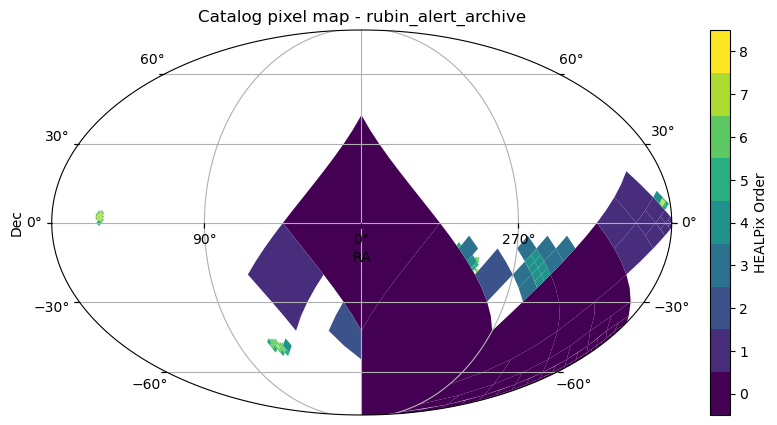

In [14]:
working_lsdb = lsdb.open_catalog(WORKING)
working_lsdb.plot_pixels()
plt.show()

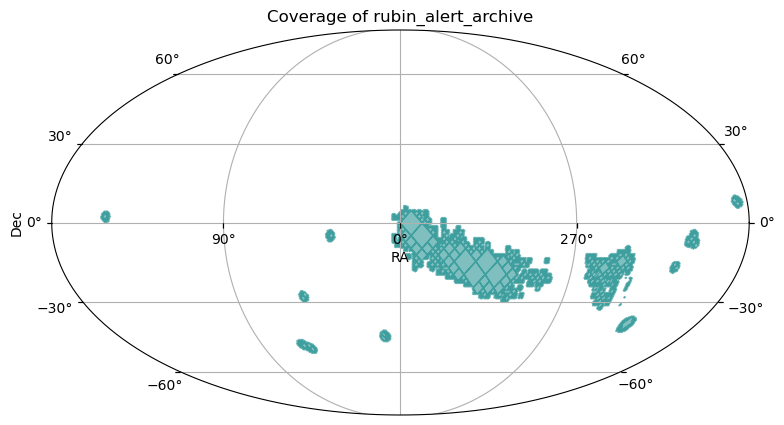

In [15]:
working_lsdb.plot_coverage()
plt.show()

## 7. Spot check against the source chunks

For a random sample of new alerts, compare the catalog's values with the ingested chunks'. They should be
identical (the import only reshapes and adds columns). The catalog's top-level `ra`/`dec` are
`diaSource.ra`/`dec`.

In [16]:
rng = np.random.default_rng(0)
sample_ids = set(rng.choice(new_ids, size=min(2000, len(new_ids)), replace=False).tolist())
pairs = {  # catalog column: chunk column
    "ra": "diaSource.ra",
    "dec": "diaSource.dec",
    "diaSource.psfFlux": "diaSource.psfFlux",
    "diaSource.midpointMjdTai": "diaSource.midpointMjdTai",
    "diaSource.band": "diaSource.band",
    "diaSource.exposureTime": "diaSource.exposureTime",
    "diaObject.diaObjectId": "diaObject.diaObjectId",
    "observation_reason": "observation_reason",
}


def sample_values(source_files, columns):
    df = pd.DataFrame({c: read_column(source_files, c).to_numpy(zero_copy_only=False) for c in ["diaSourceId", *columns]})
    return df[df["diaSourceId"].isin(sample_ids)].set_index("diaSourceId")


in_catalog = sample_values(new_files, list(pairs))
in_chunks = sample_values(ingested_files, list(dict.fromkeys(pairs.values())))
in_catalog, in_chunks = in_catalog.loc[sorted(sample_ids)], in_chunks.loc[sorted(sample_ids)]
pd.Series(
    {
        f"{cat} = {src}" if cat != src else cat: bool(
            ((in_catalog[cat] == in_chunks[src]) | (in_catalog[cat].isna() & in_chunks[src].isna())).all()
        )
        for cat, src in pairs.items()
    },
    name=f"identical across {len(sample_ids)} sampled new alerts",
).to_frame()

,identical across 2000 sampled new alerts
ra = diaSource.ra,True
dec = diaSource.dec,True
diaSource.psfFlux,True
diaSource.midpointMjdTai,True
diaSource.band,True
diaSource.exposureTime,True
diaObject.diaObjectId,True
observation_reason,True


## 8. Summary

In [17]:
nights = ", ".join(f"{d} ({n:,})" for d, n in zip(by_night["date"], by_night["total"]))
print(f"""- {len(daily_runs)} daily run(s) since the replay ingested {len(new_ids):,} alerts from {len(chunk_run)} chunks.
- Nights: {nights}.
- Catalog: {len(catalog):,} alerts in {len(now)} partitions; {int((now['rows'] > THRESHOLD).sum())} over {THRESHOLD:,} rows, largest {int(now['rows'].max()):,}.
- Raw archive: {int(raw_check['missing'].sum()):,} alerts in no chunk, {int(raw_check['waiting in landing/'].sum()):,} waiting in landing/.
- Checks: {'all passed' if all(checks.values()) else 'FAILED: ' + ', '.join(k for k, v in checks.items() if not v)}.""")

- 1 daily run(s) since the replay ingested 279,959 alerts from 7 chunks.
- Nights: 2026-10-30 (252,521), 2026-10-31 (27,438).
- Catalog: 16,746,928 alerts in 153 partitions; 6 over 200,000 rows, largest 2,172,476.
- Raw archive: 0 alerts in no chunk, 0 waiting in landing/.
- Checks: all passed.
